In [151]:
## first time series test
# append ../../ to make link to main repo work
import sys
sys.path.append('../../')
sys.path.append('/Applications/anaconda3/envs/PhD_clean/lib/python3.11/site-packages/')

import pygmt
import pandas as pd
import numpy as np
import os


In [152]:
# steps:
# 1 : load data from csv File
# 2 : plot as scatters as duration vs. rate

In [153]:
# load data

flank_motion_df = pd.read_csv('/Users/tz20896/Documents/PhD/projects/Merapi_volc/Merapi_figures/flank_motion_lit_review2.csv')
print(flank_motion_df)

# names = ['Concepcion',
#          'Colima',
#          'Cumbre Vieja 1992-2008',
#          'Damavand',
#          'Etna',
#          'Etna',
#          'Etna',
#          'Etna',
#          'Kilauea 1976-1996',
#          'Kilauea',
#          'Kilauea',
#          'Mauna Loa',
#          'Pacaya 2011-2022',
#          'Pico Island',
#          'Piton de la Fournaise',
#          'Stromboli 2008-2012',
#          'Tenerife',
#          'Vesuvius',
#          'Mount St. Helens 1980',
#          'Pacaya 2010',
#          'Pacaya 2014',
#          'Anak Krakatau 2014-2018',
#          'Anak Krakatau 2017',
#          'Anak Krakatau 2018',
#          'Arenal 2005-2008',
#          'Arenal 2011-2013',
#          'Merapi 2020',
#          'Stromboli 2007-03-09',
#          'Stromboli 2014-09-10',
#          'Stromboli 2014',
#          'Stromboli 2010-2016',
#          'Tungurahua 2015-2016',]

# names = [' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',
#          ' ',]

                      volcano   duration   disp_rate  \
0         Kilauea \n1976-1996  20.000000      20.000   
1                     Kilauea   6.000000       8.000   
2                     Kilauea   7.000000       2.000   
3                     Kilauea   0.002738   21915.000   
4                   Mauna Loa   1.000000       4.000   
5          Pacaya \n2011-2022  11.000000       1.800   
6                 Pico Island   8.000000       1.200   
7       Piton de la Fournaise   3.000000       1.400   
8                 Pacaya 2010   0.821355      12.000   
9                 Pacaya 2014   1.000000       6.000   
10                Pacaya 2010   0.002738  146100.000   
11                Pacaya 2014   0.002738   32872.500   
12                Pacaya 2021   0.002738   36525.000   
13   Cumbre Vieja \n1992-2008  16.000000       0.500   
14                       Etna   5.000000       4.000   
15                       Etna   9.000000       2.000   
16                       Etna  11.000000       1

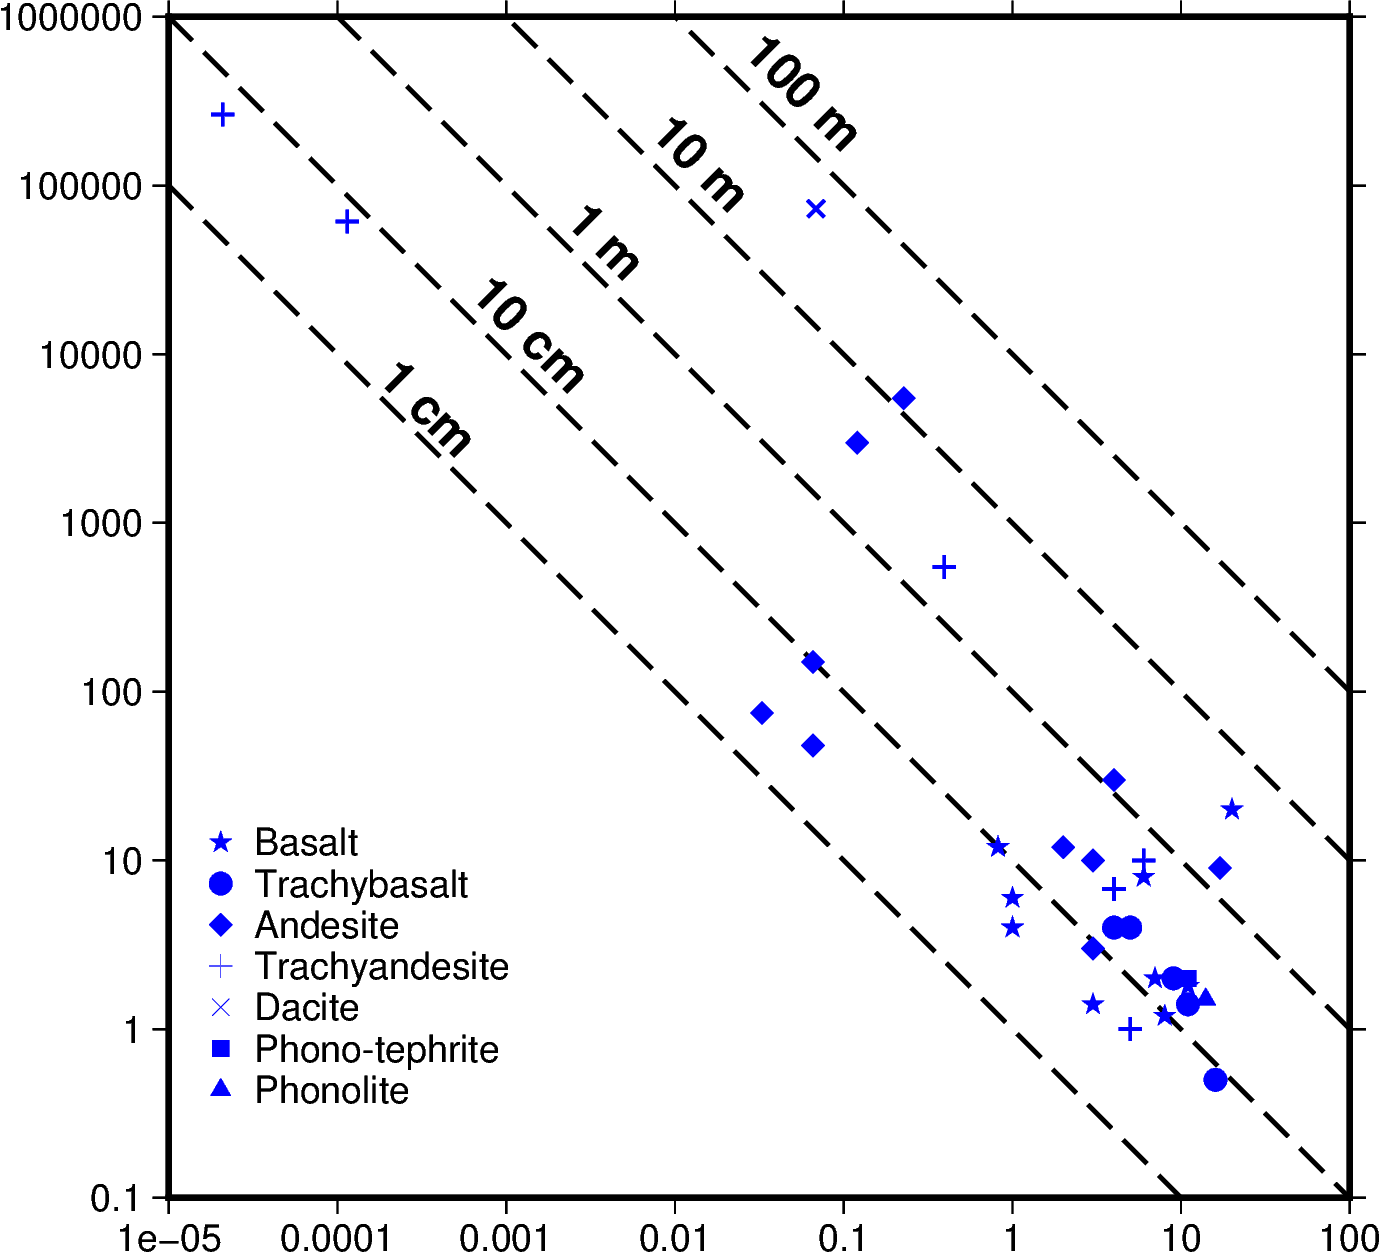

In [154]:
PROJECTION = "X10cl/10cl",
REGION=[1e-5, 100, 1e-1, 1e6]


fig = pygmt.Figure()


# # plot total disp guide lines
fig.plot(region=REGION,projection=PROJECTION,frame=["WSne", "xa1", "ya1"],x=[1e-5, 100000] ,y=[1e9,0.1], pen="1p,black,-",)
fig.plot(x=[1e-5, 10000]  ,y=[1e8,0.1], pen="1p,black,-",)
fig.plot(x=[1e-5, 1000]   ,y=[1e7,0.1], pen="1p,black,-",)
fig.plot(x=[1e-5, 100]    ,y=[1e6,0.1], pen="1p,black,-",)
fig.plot(x=[1e-5, 10]     ,y=[1e5,0.1], pen="1p,black,-",)

#          
styles     = ['a0.2c', 'c0.2c', 'd0.2c','+0.2c','x0.2c','s0.2c', 't0.2c','t0.2c+ap60']
label_flag = [1, 1, 1, 1, 1, 1, 1 ]
labels = ['Basalt','Trachybasalt','Andesite','Trachyandesite','Dacite','Phono-tephrite','Phonolite']
for (rock_id, duration,rate,inst) in zip(flank_motion_df['rock_type_number'],flank_motion_df['duration'], flank_motion_df['disp_rate'],flank_motion_df['instant']):
    if inst:
        continue
        # if label_flag[rock_id-1]:
        #             fig.plot(
        #                 x=duration,
        #                 y=rate,
        #                 # Set the line thickness to "1p", the color to "blue",
        #                 # and the style to "-", i.e. "dashed"
        #                 style=styles[rock_id-1],
        #                 fill='red',
        #                 label=labels[rock_id-1],
        #                 )
        #             label_flag[rock_id-1] = 0

        # else:
        #     fig.plot(
        #         x=duration,
        #         y=rate,
        #         # Set the line thickness to "1p", the color to "blue",
        #         # and the style to "-", i.e. "dashed"
        #         style=styles[rock_id-1],
        #         fill='red',
        #         )
    else:
        if label_flag[rock_id-1]:
            fig.plot(
                x=duration,
                y=rate,
                # Set the line thickness to "1p", the color to "blue",
                # and the style to "-", i.e. "dashed"
                style=styles[rock_id-1],
                fill='blue',
                label=labels[rock_id-1],
                )
            label_flag[rock_id-1] = 0
        else:
            fig.plot(
                x=duration,
                y=rate,
                # Set the line thickness to "1p", the color to "blue",
                # and the style to "-", i.e. "dashed"
                style=styles[rock_id-1],
                fill='blue',
                )
            

fig.legend(position='JBL+jBL+o0.2c/0.6c')

# Create space-delimited file
with open("texts.txt", "w") as f:
    f.write(f"{1.7e-4}  {7e3}    -45 12p,Helvetica-Bold,black BL 1 cm\n")
    f.write(f"{6e-4}    {2.2e4}  -45 12p,Helvetica-Bold,black BL 10 cm\n")
    f.write(f"{2.2e-3}     {6e4}   -45 12p,Helvetica-Bold,black BL 1 m\n")
    f.write(f"{7e-3}     {2e5}   -45 12p,Helvetica-Bold,black BL 10 m\n")
    f.write(f"{2.5e-2}     {6e5}   -45 12p,Helvetica-Bold,black BL 100 m\n")
fig.text(textfiles="texts.txt", angle=True, font=True, justify=True)


# for (name, x_pos,y_pos,plot_flag,text_x,text_y,anchor) in zip(names,flank_motion_df['duration'], flank_motion_df['disp_rate'],flank_motion_df['plot_flag'],flank_motion_df['text_x'],flank_motion_df['text_y'],flank_motion_df['anchor']):
#     print((name, x_pos,y_pos))
#     if plot_flag:
# #                 ax.annotate(name,
# #                         xy=(x_pos,y_pos),xycoords='data',
# #                         xytext=(text_x,text_y),textcoords='offset points',
# #                         arrowprops=arpr,)
#         with open("texts2.txt", "w") as f:
#             f.write(f"{x_pos} {y_pos} 0 10p,Helvetica-Bold,black {anchor} {name}\n")
#         fig.text(textfiles="texts2.txt", angle=True, font=True, justify=True,region=REGION,offset=f'j{text_x/30}/{text_y/30}+v2p,black',)

# Cleanups
os.remove("texts.txt")
# os.remove("texts2.txt")

fig.show()



In [155]:
# %matplotlib osx
# # plot results
# plt.close('all')
# fig, ax = plt.subplots(1,1,figsize=(8,8))

# # plot total disp guide lines
# ax.plot([1e-5, 100000] ,[1e9,0.1], color='black', linestyle='--')
# ax.plot([1e-5, 10000]  ,[1e8,0.1], color='black', linestyle='--')
# ax.plot([1e-5, 1000]   ,[1e7,0.1], color='black', linestyle='--')
# ax.plot([1e-5, 100]    ,[1e6,0.1], color='black', linestyle='--')
# ax.plot([1e-5, 10]     ,[1e5,0.1], color='black', linestyle='--')

# # plot duraton vs. rate
# ax.scatter(flank_motion_df['duration'], flank_motion_df['disp_rate'],10)

# # set log scale
# ax.set_yscale('log')
# ax.set_xscale('log')

# # set labels and limits
# ax.set_xlabel('Duration [years]')
# ax.set_ylabel('Displacement rate [cm/yr]')
# ax.set_xlim([1e-5,100])
# ax.set_ylim([1e-1,1e6])

# # annotate data
# annot_flag = []
# arpr = {"arrowstyle": "-",}

# for (name, x_pos,y_pos,plot_flag,text_x,text_y) in zip(names,flank_motion_df['duration'], flank_motion_df['disp_rate'],flank_motion_df['plot_flag'],flank_motion_df['text_x'],flank_motion_df['text_y']):
#         print((name, x_pos,y_pos))
#         if plot_flag:
#                 ax.annotate(name,
#                         xy=(x_pos,y_pos),xycoords='data',
#                         xytext=(text_x,text_y),textcoords='offset points',
#                         arrowprops=arpr,)
                
# # add text for total disp lines
# ax.text(x=1.7e-4,
#         y=0.4e4,
#         s='1 cm',
#         rotation = -45)

# ax.text(x=0.5e-3,
#         y=1.2e4,
#         s='10 cm',
#         rotation = -45)

# ax.text(x=0.5e-3,
#         y=1.2e4,
#         s='1 m',
#         rotation = -45)


